#### PCA - Principal Component Analysis
Very useful in noise/redundancy reduction => reduce amount of variables by creating hybrid variables (principal components).

You can also use clustering in order to visualize how easily separated the data is.

In [1]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import LabelEncoder

# load data 
df = pd.read_csv("HeartDisease_cleaned.csv")
df = df.drop_duplicates()

df.head()

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST
0,40,1,140,289,0,172,0,0.0,3,0,0,1,0,0,0,1,0
1,49,0,160,180,0,156,0,1.0,2,1,0,0,1,0,0,1,0
2,37,1,130,283,0,98,0,0.0,3,0,0,1,0,0,0,0,1
3,48,0,138,214,0,108,1,1.5,2,1,1,0,0,0,0,1,0
4,54,1,150,195,0,122,0,0.0,3,0,0,0,1,0,0,1,0


In [2]:
# the original dataset has 12 columns
len(df.columns)

17

#### Scale the values and perform PCA on our data (X/y)

Explained variance ratio with 8 components, by each component:
[0.20902865 0.11653604 0.09450439 0.084963   0.07251278 0.07092925
 0.06208129 0.05471577]

Explained variance ratio with 8 components, total result:
0.7652711877046214

Mean Squared Error (MSE) between original and reconstructed data:
0.23472881229537873
Average MSE per feature: 0.014671


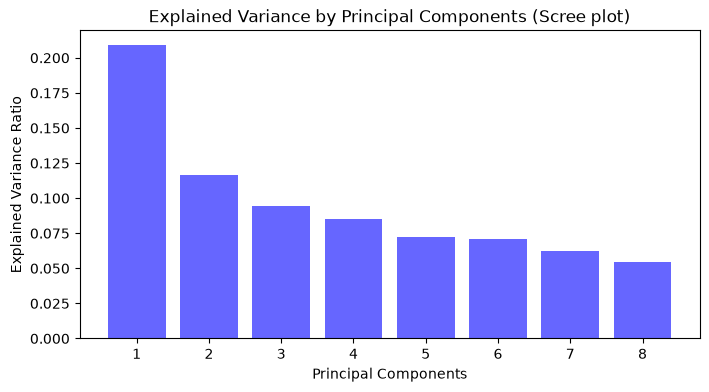

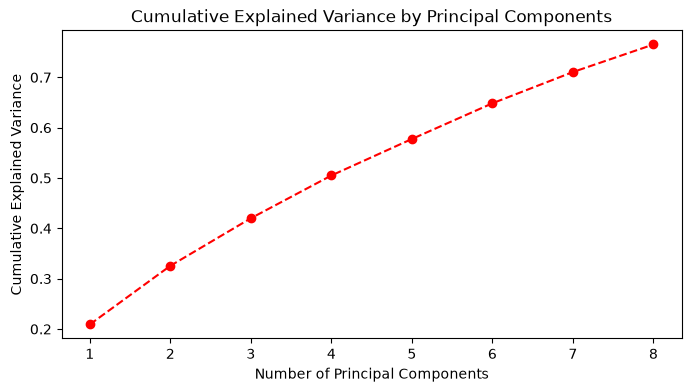

In [3]:
# X/y -split and scale the values
X = df.drop("HeartDisease", axis=1)
y = df['HeartDisease']

# scaling is needed in PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# define amount of PCA-variables => principal components
num_components = 8

# train the PCA -model
pca = PCA(n_components=num_components)
X_pca = pca.fit_transform(X_scaled)

# some basic metrics
explained_variance_ratio = pca.explained_variance_ratio_

print(f"Explained variance ratio with {num_components} components, by each component:\n{explained_variance_ratio}")
print(f"\nExplained variance ratio with {num_components} components, total result:\n{sum(explained_variance_ratio)}")

# 0.798 ~~ 80% of data preserved, which means we lost 20% of variance in the process
# aim to have less than 10% lost, or even less than 5% lost

X_reconstructed = pca.inverse_transform(X_pca)

# other metric is MSE => keep this as close to 0 as possible
# basically measures how much error the PCA model makes compared to original data
mse = mean_squared_error(X_scaled, X_reconstructed)
print(f"\nMean Squared Error (MSE) between original and reconstructed data:\n{mse}")
print(f"Average MSE per feature: {mse / X_scaled.shape[1]:.6f}")

# plot variance plots to see how much different components add to explainability
# plot 1: SCREE PLOT
plt.figure(figsize=(8, 4))
plt.bar(range(1, num_components + 1, ), explained_variance_ratio, alpha=0.6, color="b")
plt.xlabel("Principal Components")
plt.ylabel("Explained Variance Ratio")
plt.title("Explained Variance by Principal Components (Scree plot)")
plt.show()

# plot 2: cumulative explained variance
cumulative_variance = explained_variance_ratio.cumsum()
plt.figure(figsize=(8, 4))
plt.plot(range(1, num_components + 1, ), cumulative_variance, marker="o", linestyle='--', color="r")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance by Principal Components")
plt.show()

In [4]:
# get the component loadings
loadings = pca.components_

# create a DataFrame
loadings_df = pd.DataFrame(
    loadings.T,
    columns=[f"PC{i + 1}" for i in range(loadings.shape[0])], index=X.columns
)

In [5]:
loadings_df

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
Age,0.290926,-0.195373,0.089972,0.126291,0.282373,0.126395,-0.377128,-0.047846
Sex,0.183603,0.151566,0.157004,0.051930,-0.236128,0.099565,0.167744,0.865769
RestingBP,0.137572,-0.187606,-0.073661,-0.043045,0.571014,0.172587,-0.230805,0.293429
Cholesterol,-0.134574,-0.225925,-0.486713,-0.112606,0.222046,-0.135816,0.113193,0.049907
FastingBS,0.173953,0.001418,0.346913,0.074886,-0.107025,0.323152,-0.323395,-0.171303
MaxHR,-0.339273,-0.166947,-0.140436,-0.001148,-0.170823,0.049705,0.213674,-0.014603
ExerciseAngina,0.369619,0.092890,-0.189817,-0.019657,0.115787,-0.182793,0.131704,0.105903
Oldpeak,0.318848,-0.076115,-0.294152,0.113810,0.161272,0.035026,0.309649,-0.049086
ST_Slope,-0.371183,-0.026563,0.139083,-0.179678,-0.032012,-0.043323,-0.179048,0.145573
ChestPainType_ASY,0.384875,0.199714,-0.185951,-0.270302,-0.304849,-0.091399,-0.116548,-0.144663


<Axes: >

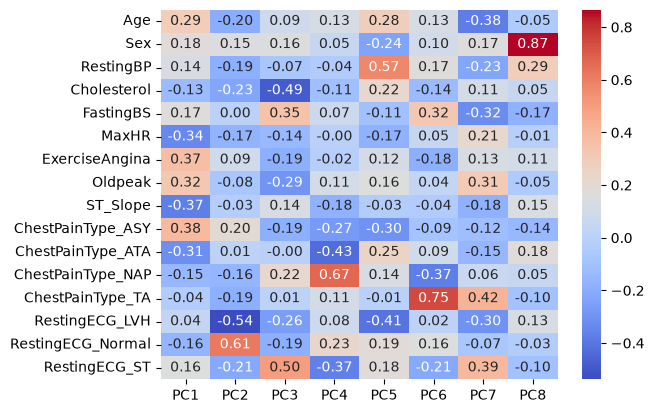

In [6]:
# use heatmap for colorization
sns.heatmap(loadings_df, annot=True, fmt=".2f", cmap="coolwarm")

PCA reduced 16 features to 8, but it kept only 76.5% of the variance. The variance is spread fairly evenly over the components. This is because many features are one-hot dummy columns (ChestPainType and RestingECG), and binary columns do not compress well. PCA is therefore only moderately useful here. The components also have a cost in interpretability. PC1 is a mixture of several features, while the original features such as ST_Slope are easier to explain. 

Data Analysis - point of view -> finding noise etc. OPTIONAL TASK!

This version compares the Principal Components to each other.

Usually you wish to see great separation between categories => this way there's not much overlap between them.

However, this dataset is a mess when it comes to overlap. Would probably be a good idea to generate more data with SMOTE to fix the distribution.

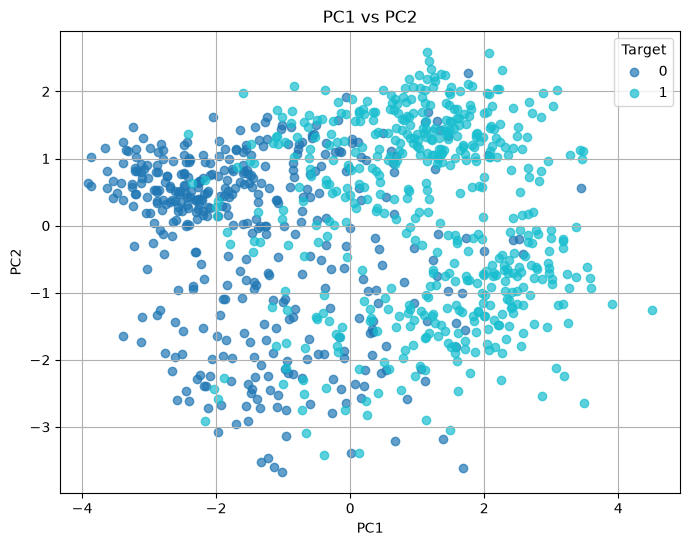

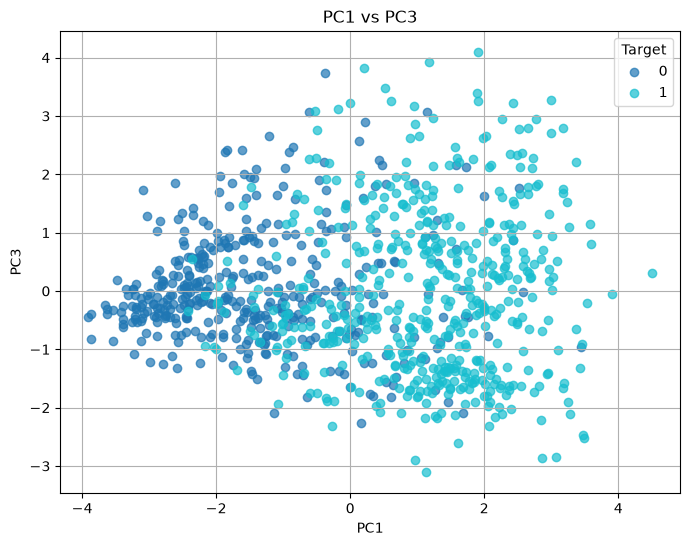

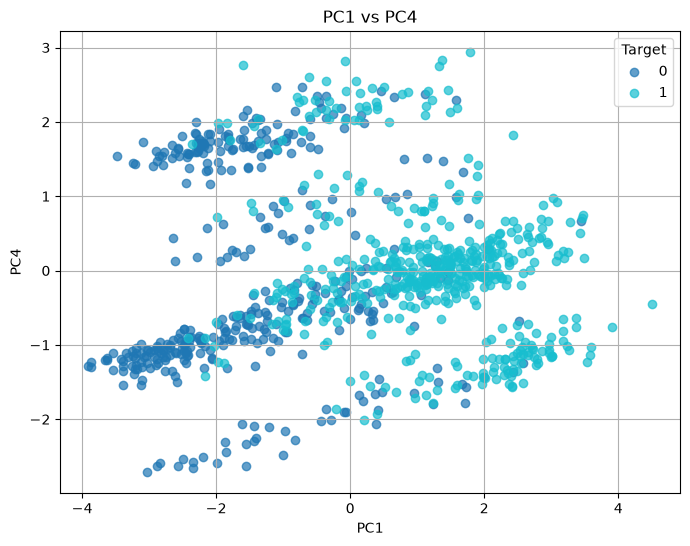

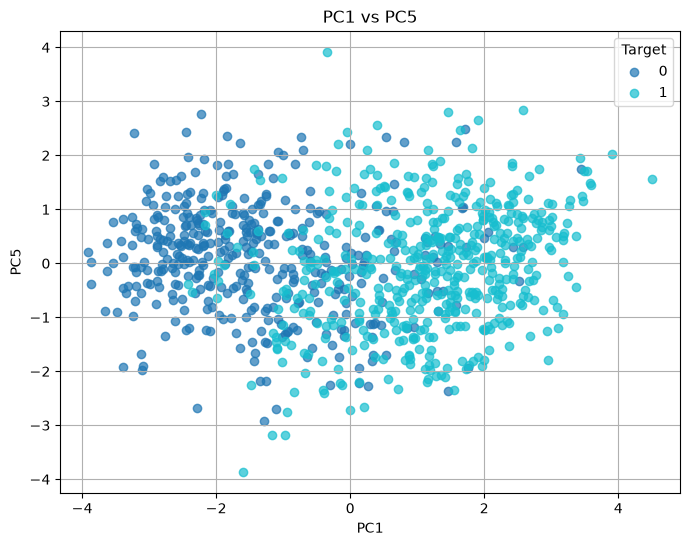

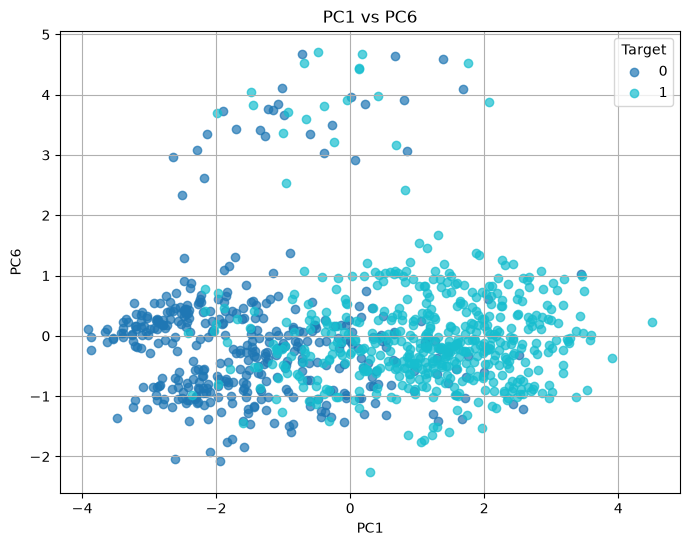

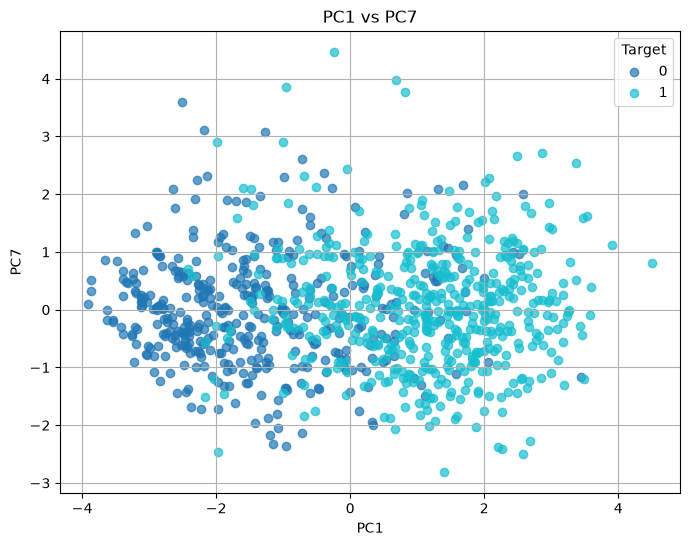

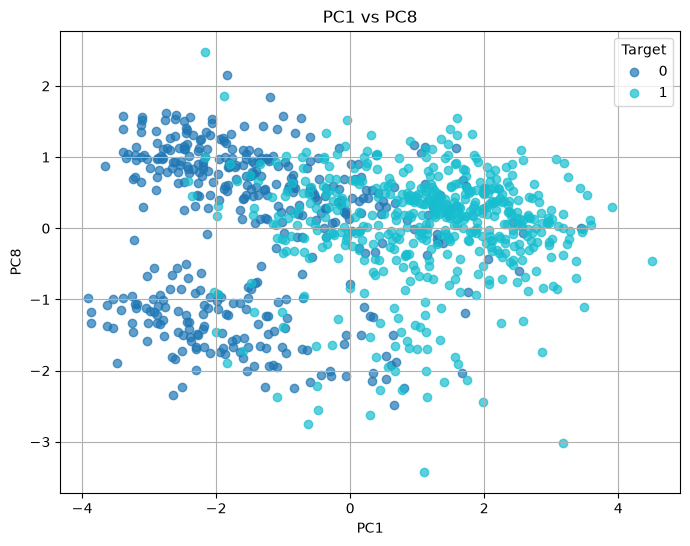

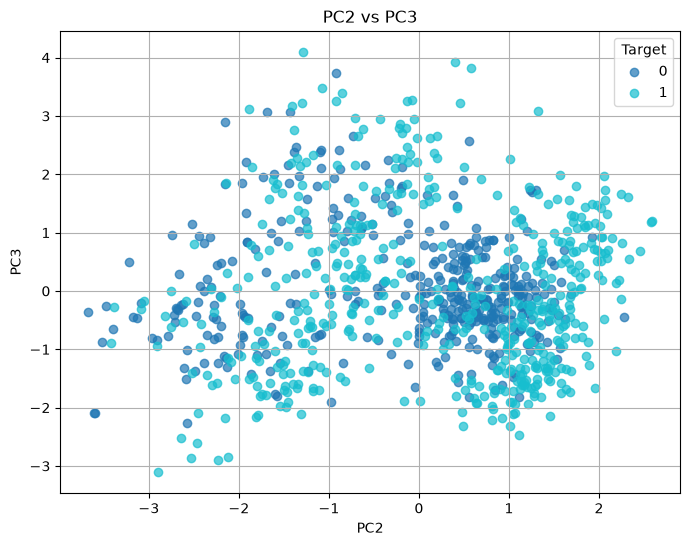

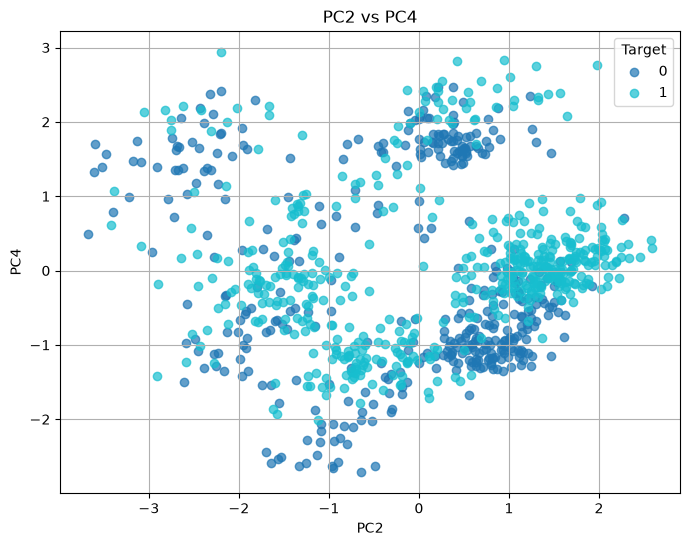

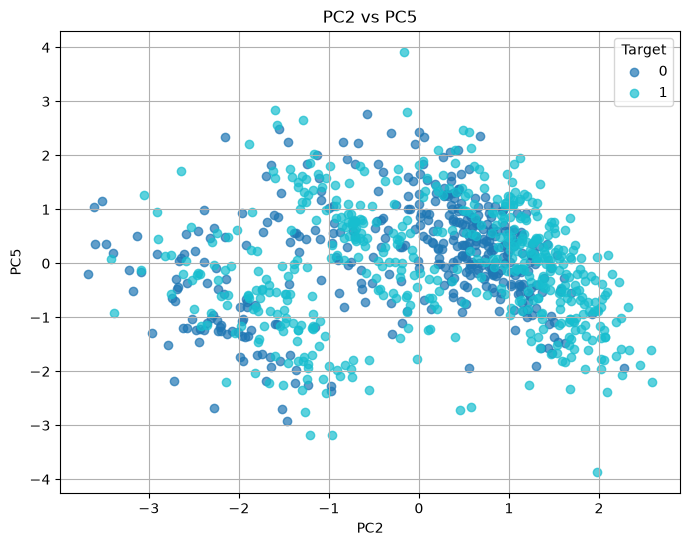

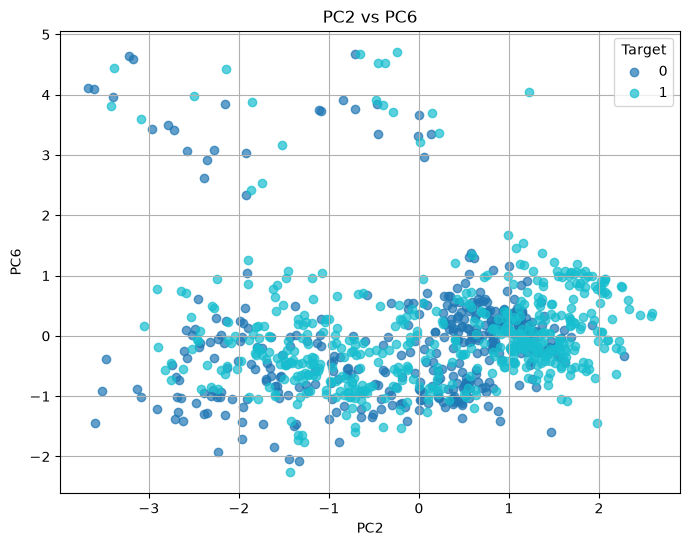

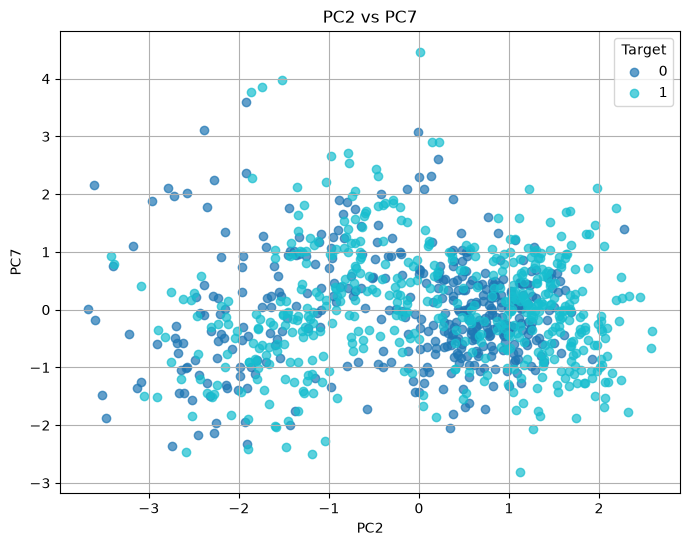

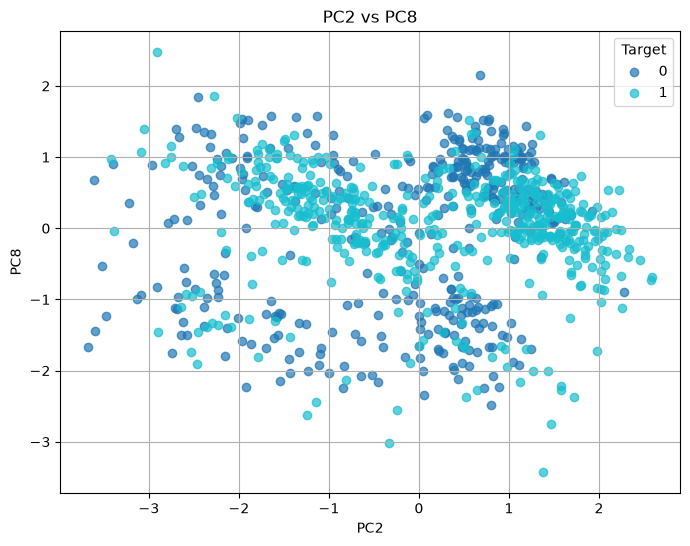

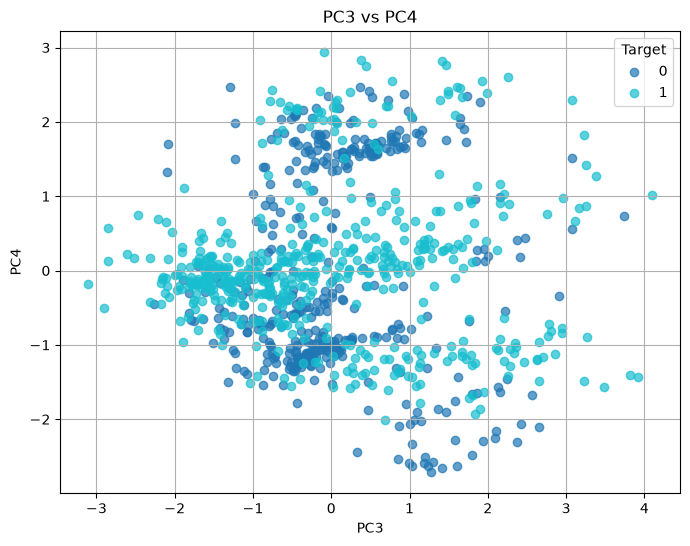

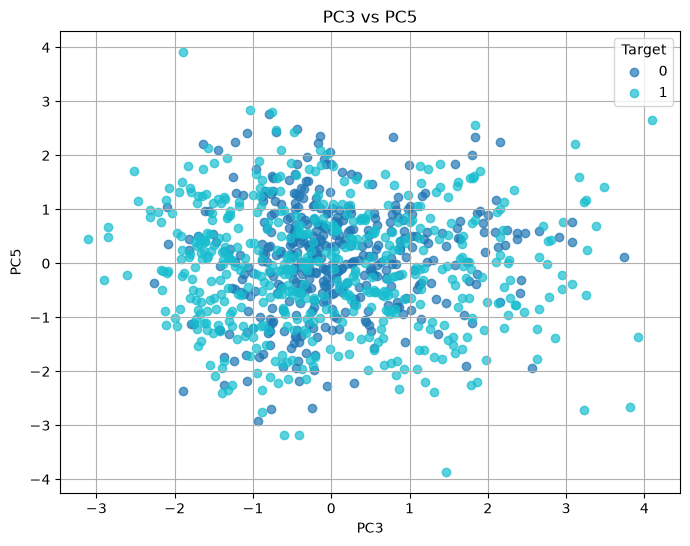

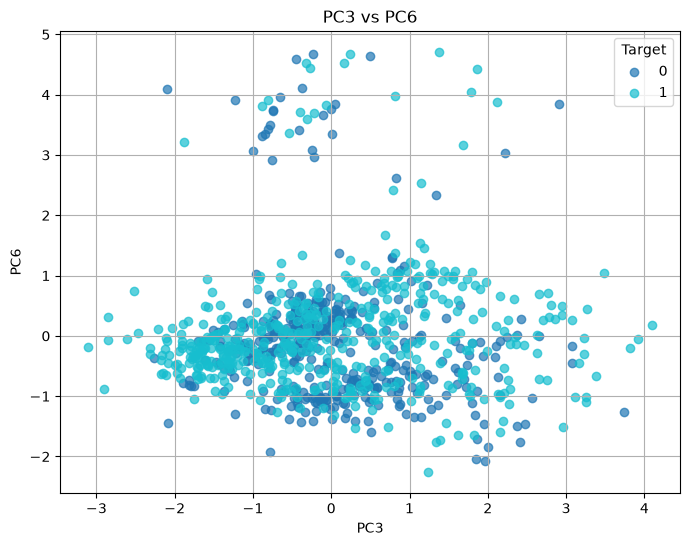

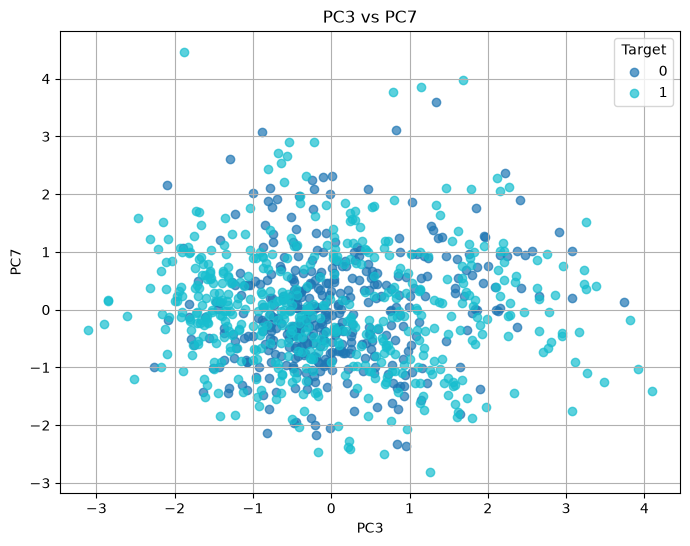

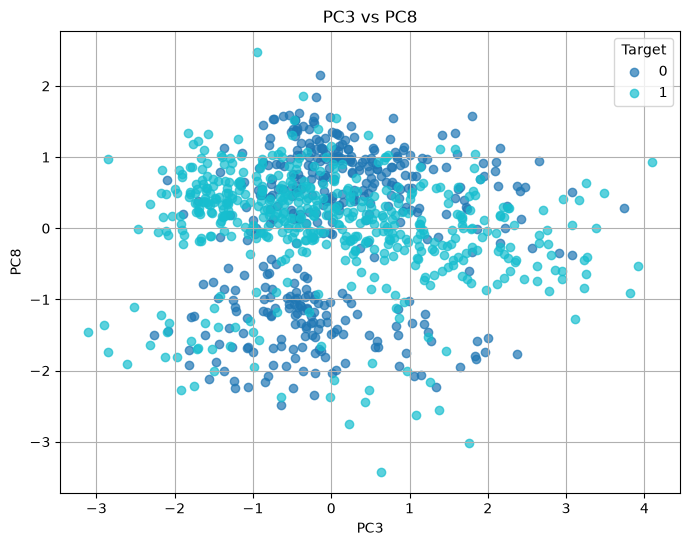

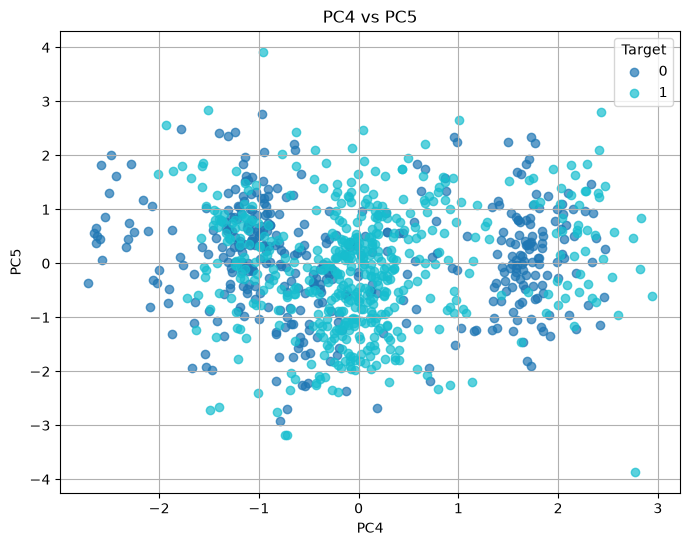

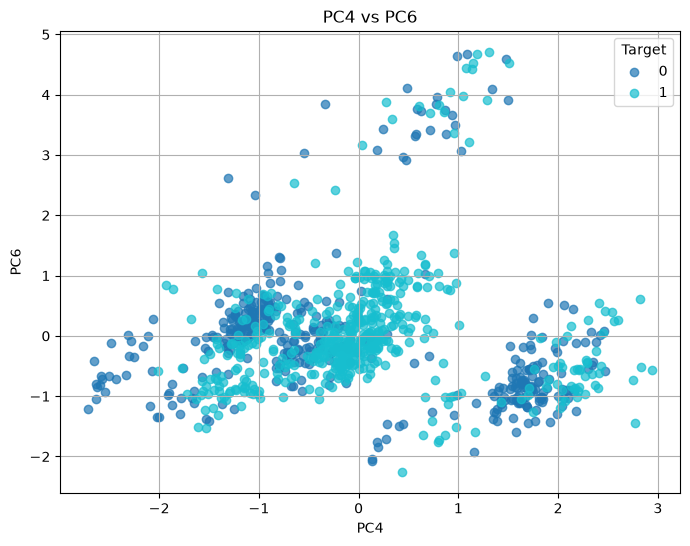

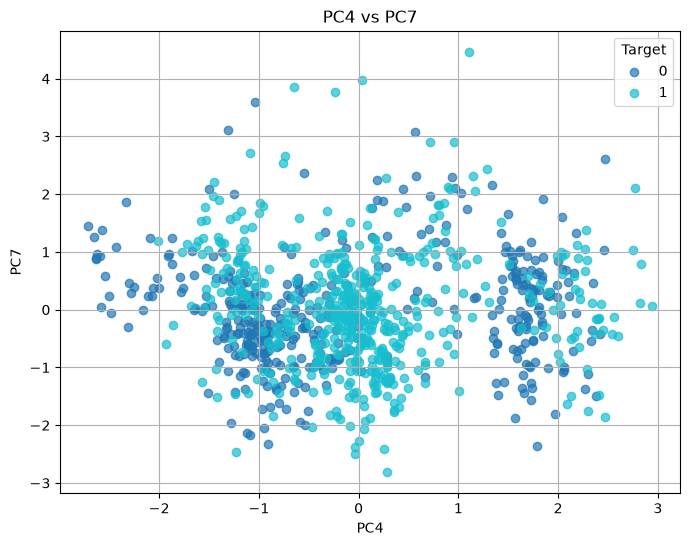

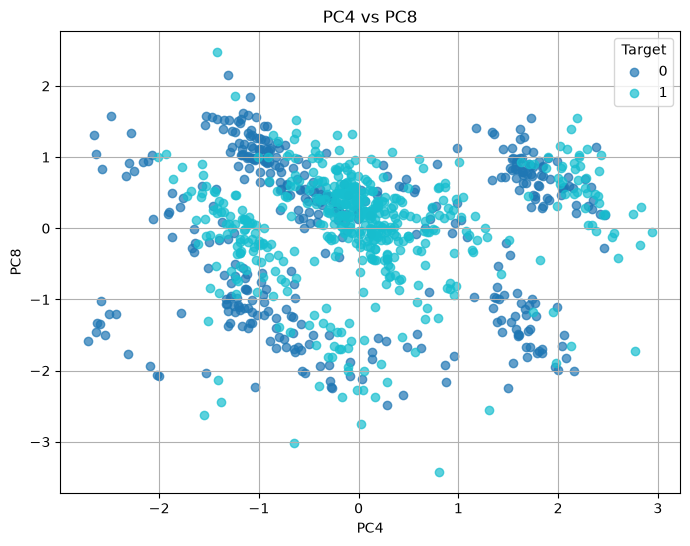

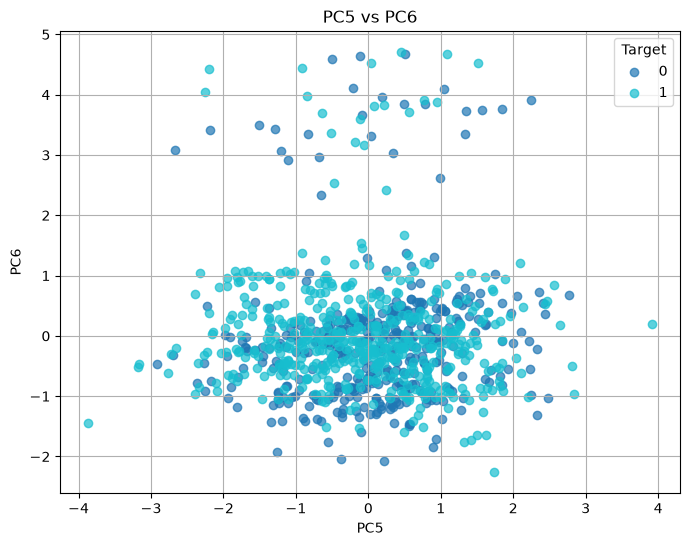

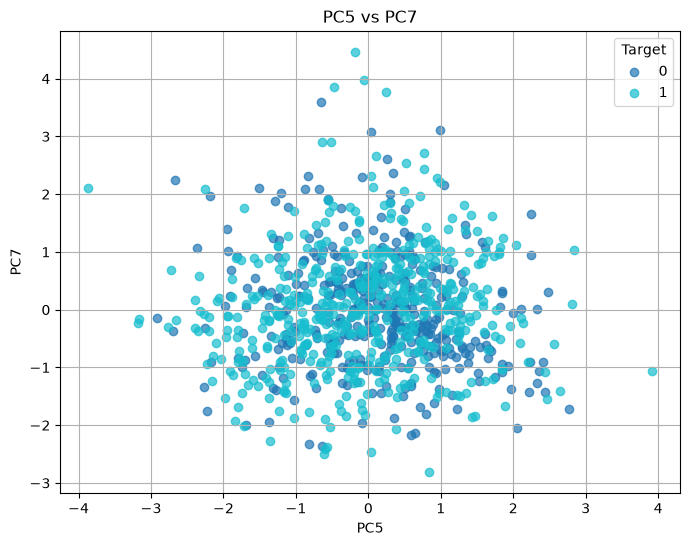

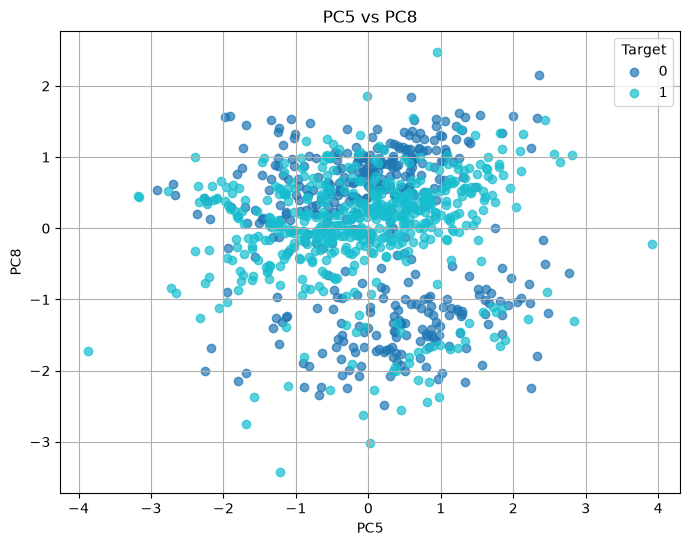

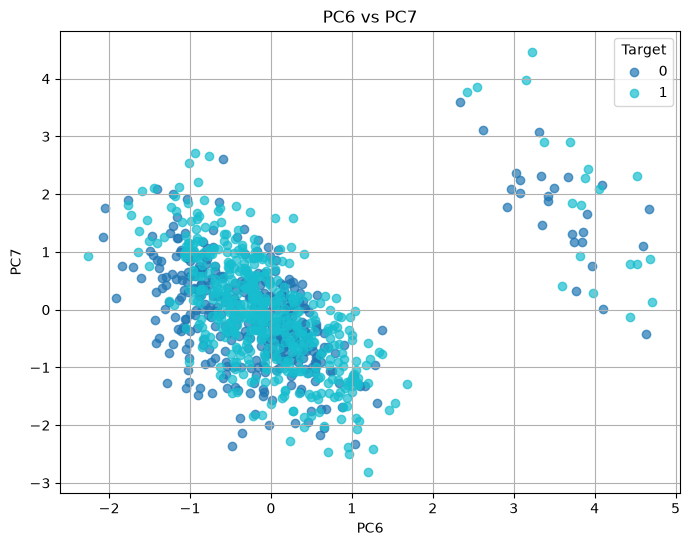

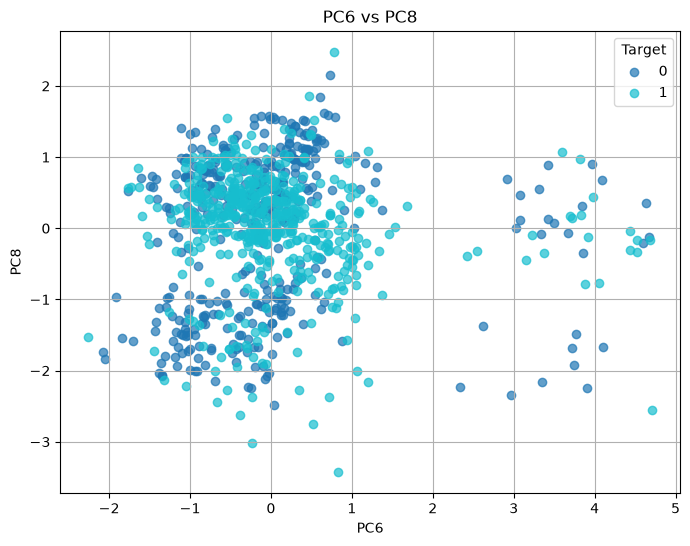

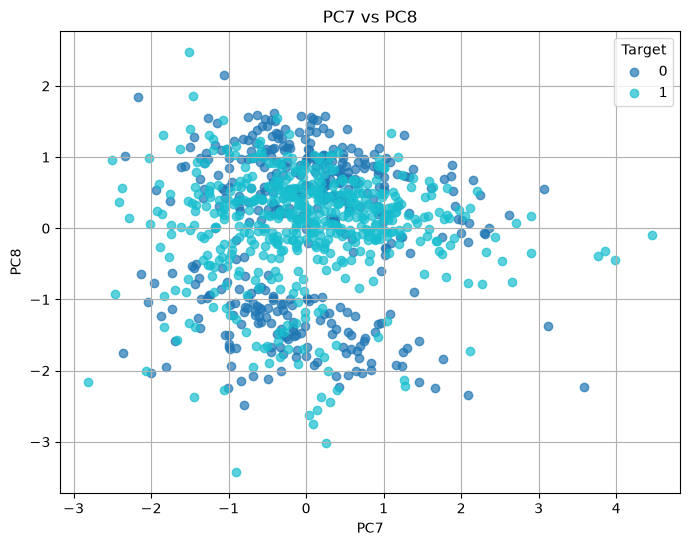

In [7]:
# helper functions to compare and visualize PC-variables

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)

def plot_pca_pairs(pca_result, components, target=None):
    num_c = pca_result.shape[1]

    # Get unique target classes
    if target is not None:
        classes = np.unique(target)
        colors = plt.cm.tab10(np.linspace(0, 1, len(classes)))

    # Process each pair of PC variables
    for i in range(num_c):
        for j in range(i + 1, num_c):
            plt.figure(figsize=(8, 6))

            if target is not None:
                for cls, color in zip(classes, colors):
                    mask = target == cls

                    plt.scatter(
                        pca_result[mask, i],
                        pca_result[mask, j],
                        color=color,
                        alpha=0.7,
                        label=str(cls)
                    )

                plt.legend(title="Target")

            else:
                plt.scatter(
                    pca_result[:, i],
                    pca_result[:, j],
                    alpha=0.7
                )

            plt.title(f"PC{i+1} vs PC{j+1}")
            plt.xlabel(f"PC{i+1}")
            plt.ylabel(f"PC{j+1}")
            plt.grid(True)
            plt.show()

def plot_pca_pairs_with_clustering(pca_result, components, n_clusters=3):
    num_c = pca_result.shape[1]
    
    # Apply KMeans clustering
    kmeans = KMeans(n_clusters=n_clusters, random_state=1874)
    cluster_labels = kmeans.fit_predict(pca_result)
    
    # Process each pair of PC-variables and plot clusters
    for i in range(num_c):
        for j in range(i + 1, num_c):
            plt.figure(figsize=(8, 6))
            scatter = plt.scatter(pca_result[:, i], pca_result[:, j], c=cluster_labels, cmap='viridis', alpha=0.7)
            plt.title(f"PC{i+1} vs PC{j+1}")
            plt.xlabel(f"PC{i+1}")
            plt.ylabel(f"PC{j+1}")
            plt.grid(True)
            plt.colorbar(scatter, label='Cluster')
            plt.show()

    comparison = pd.crosstab(
        pd.Series(cluster_labels, name="Cluster"),
        pd.Series(y, name="Quality")
    )

    sns.heatmap(comparison, annot=True, fmt="d", cmap="Blues")

    plt.title("KMeans Clusters vs Actual Wine Quality")
    plt.show()

    print("Silhouette:",
      silhouette_score(pca_result, cluster_labels))

    print("Davies-Bouldin:",
        davies_bouldin_score(pca_result, cluster_labels))

    print("ARI:",
        adjusted_rand_score(y, cluster_labels))

    print("NMI:",
        normalized_mutual_info_score(y, cluster_labels))

plot_pca_pairs(X_pca, pca.components_, y)
# we can also use KMeans to visualize how well the data can be differentiated
# 3 is a good number to begin with for clusters, try also 6 (amount of options in the target)
# plot_pca_pairs_with_clustering(X_pca, pca.components_, n_clusters=8)

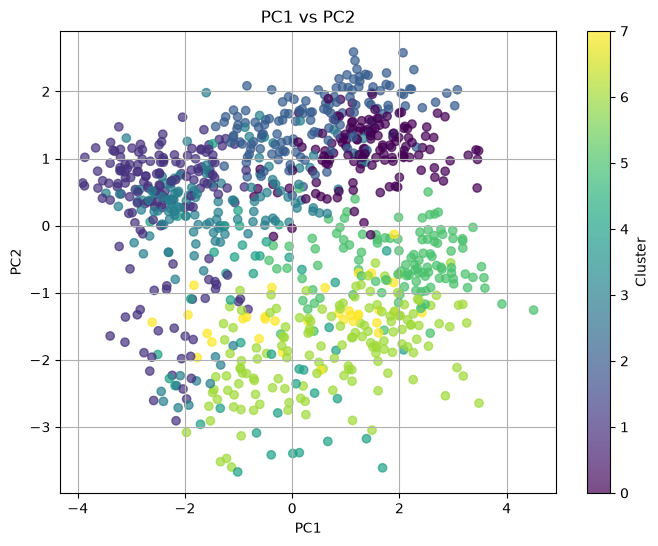

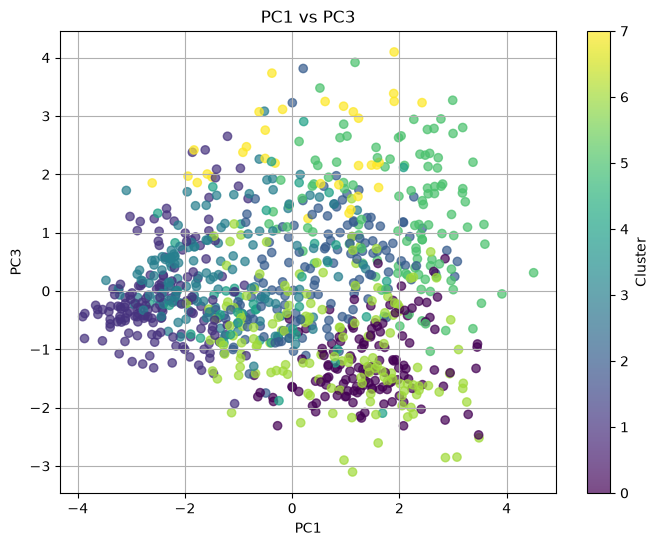

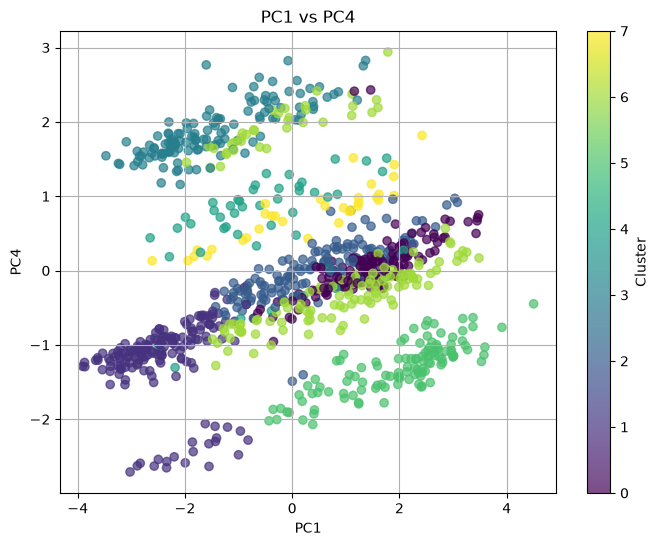

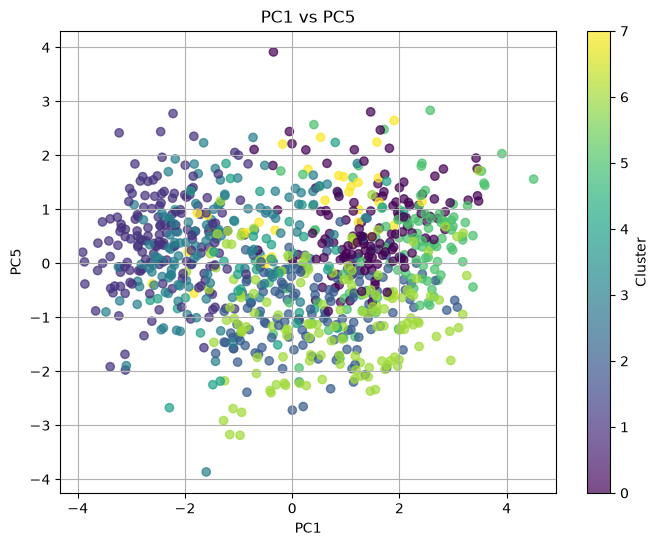

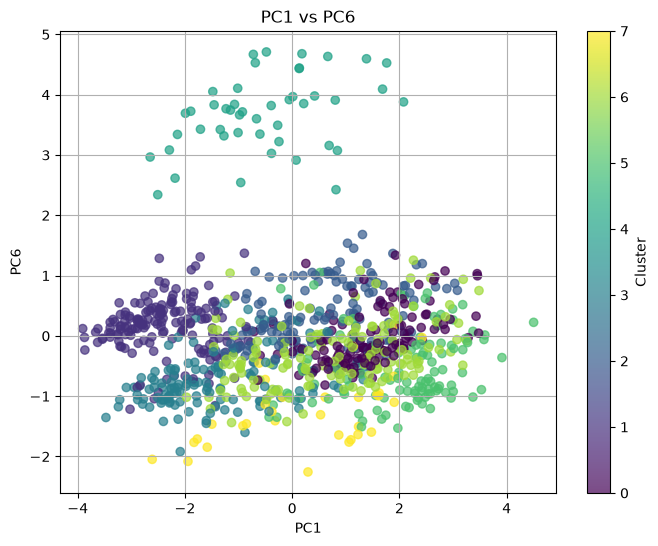

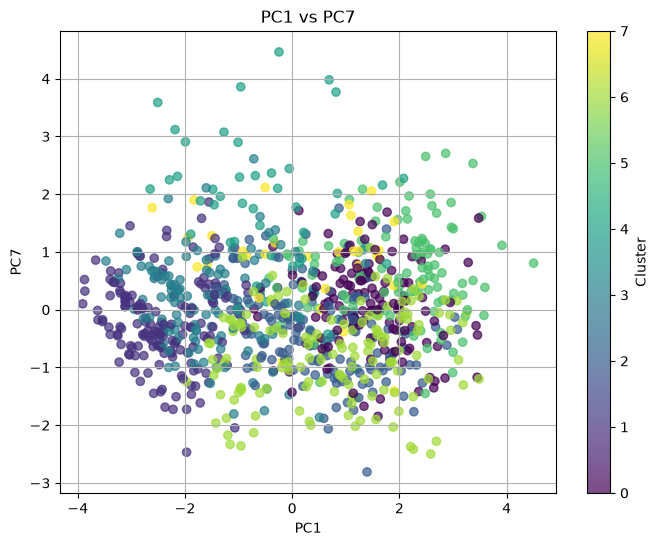

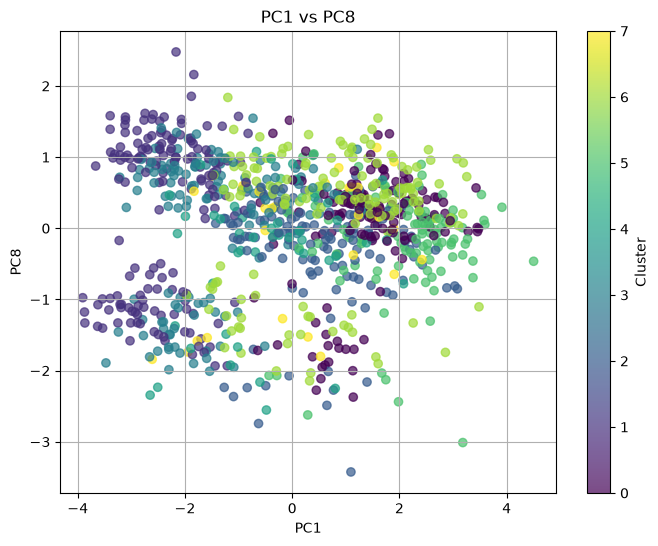

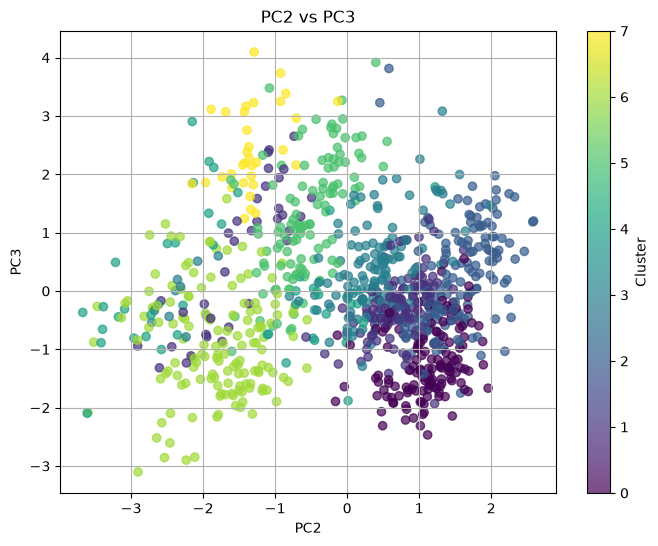

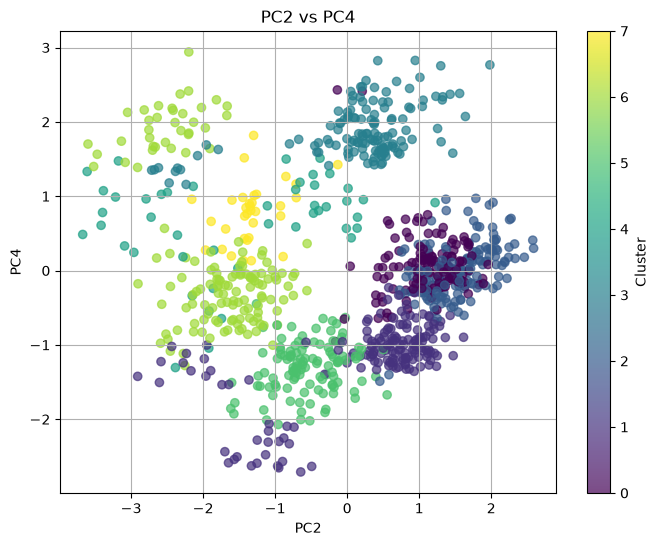

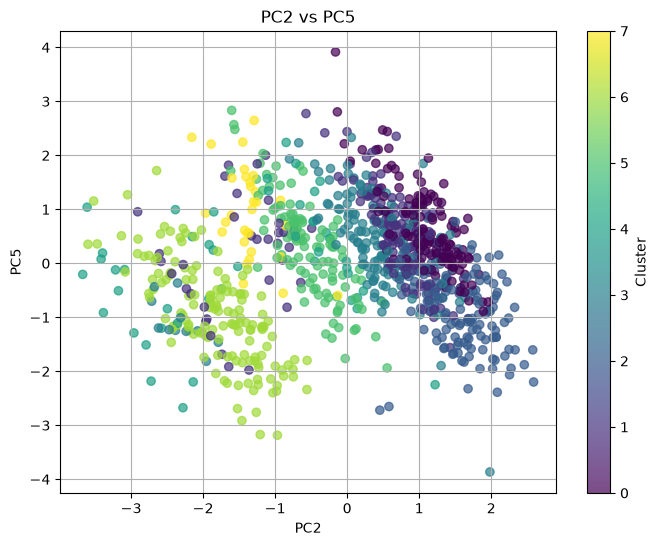

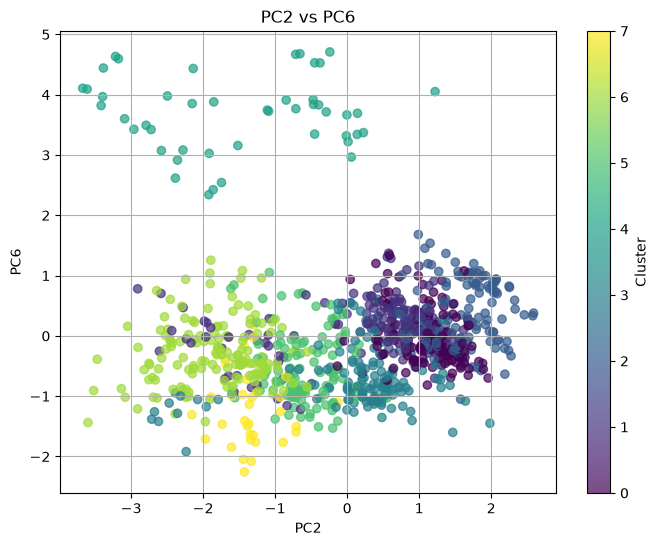

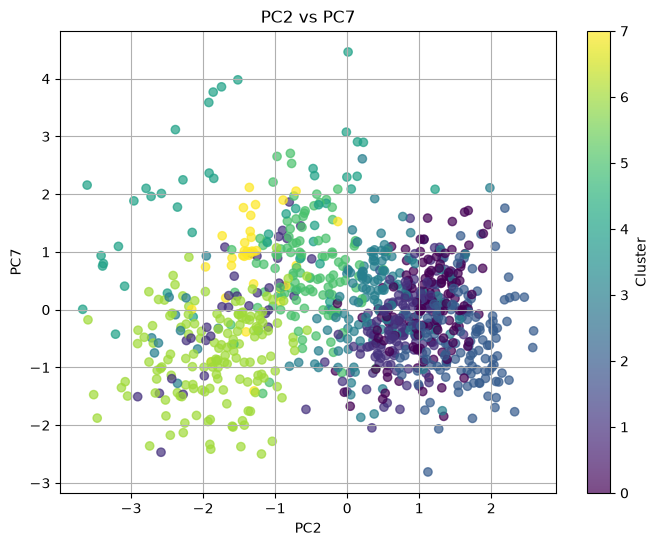

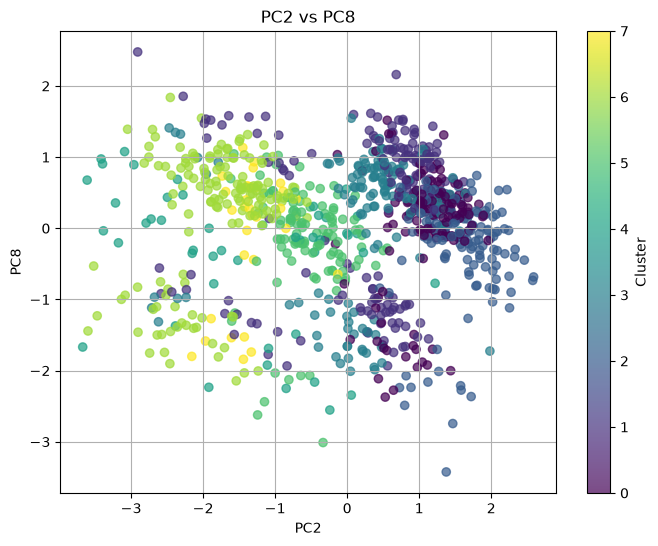

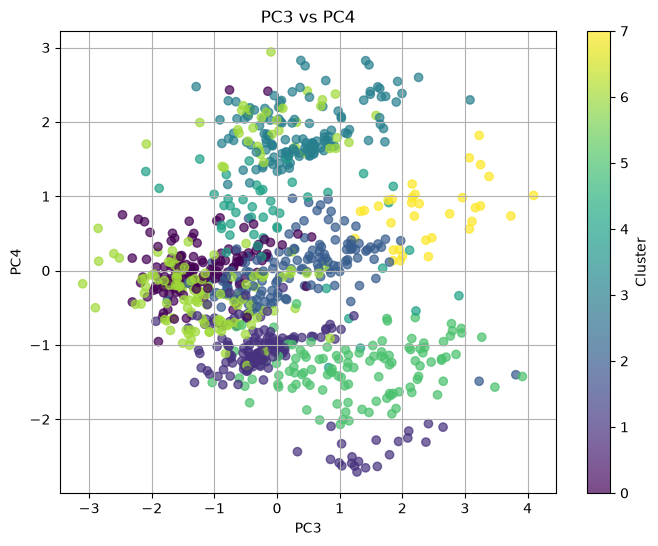

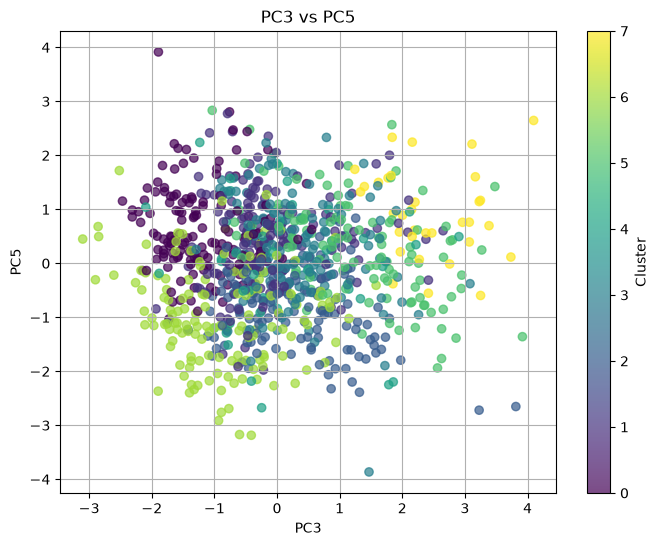

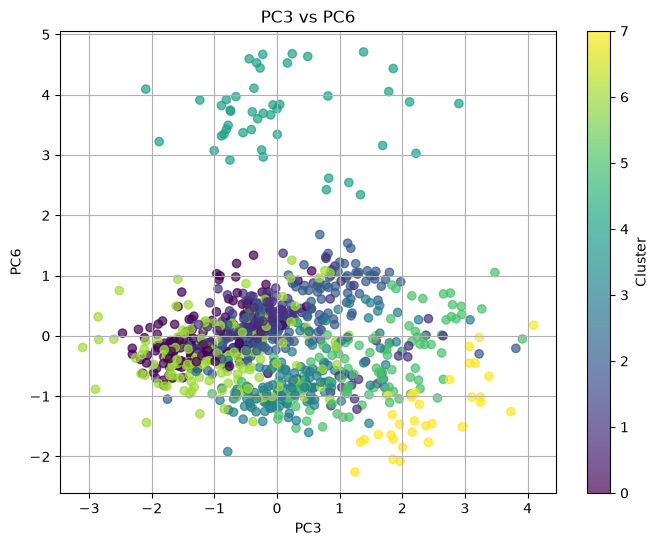

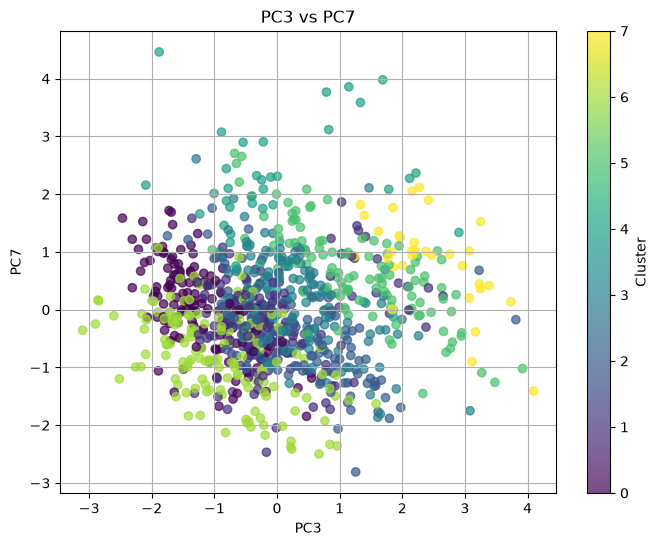

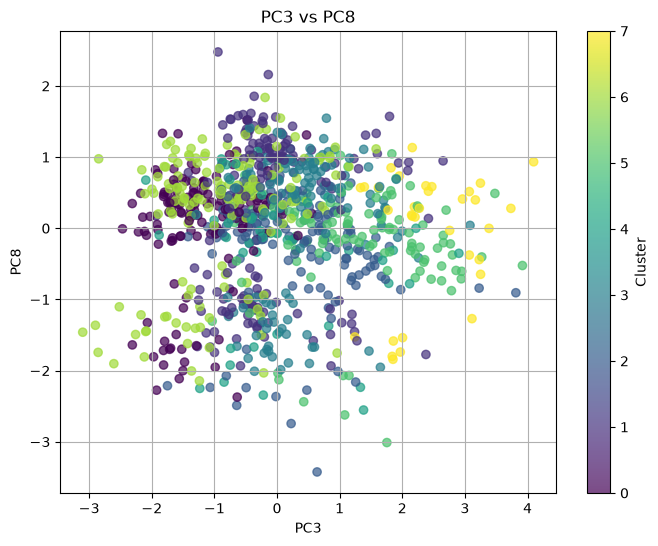

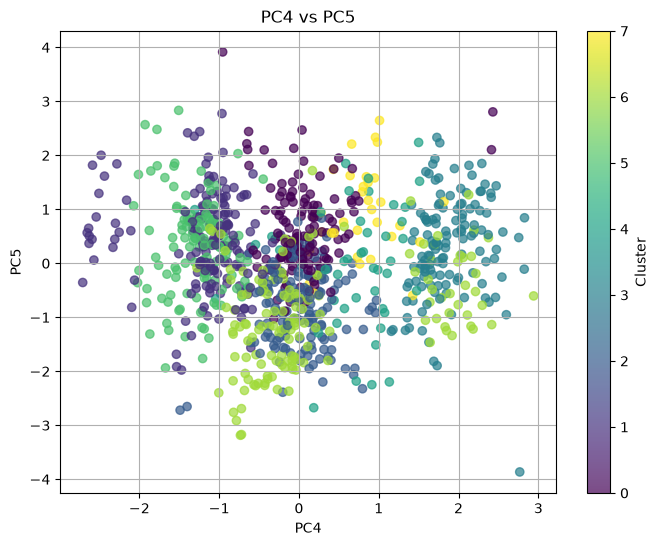

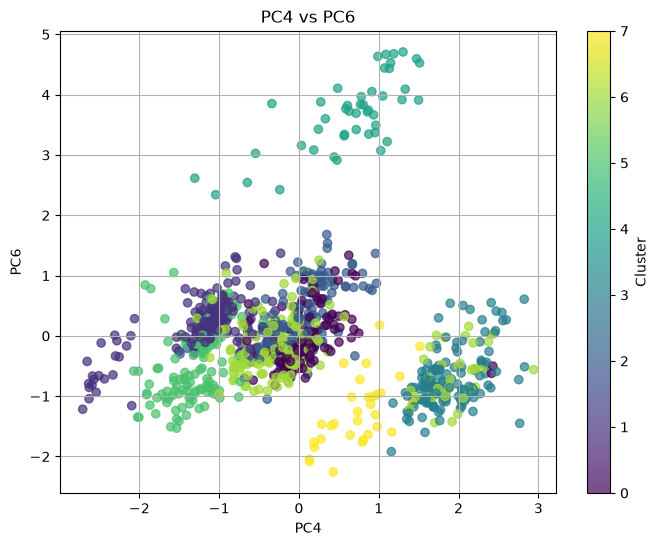

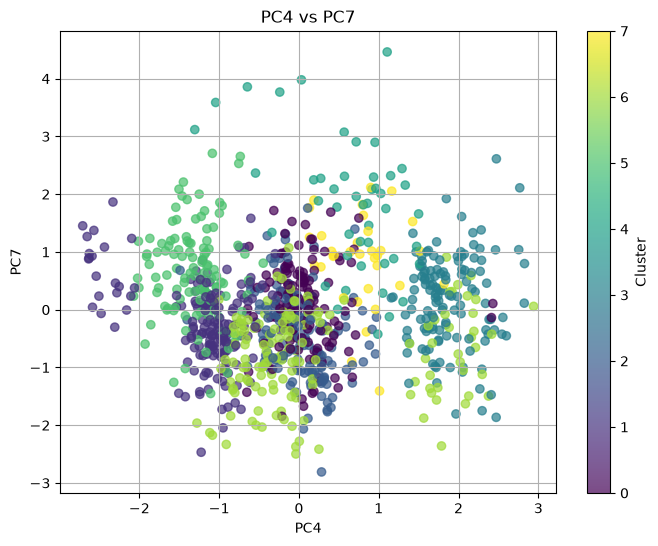

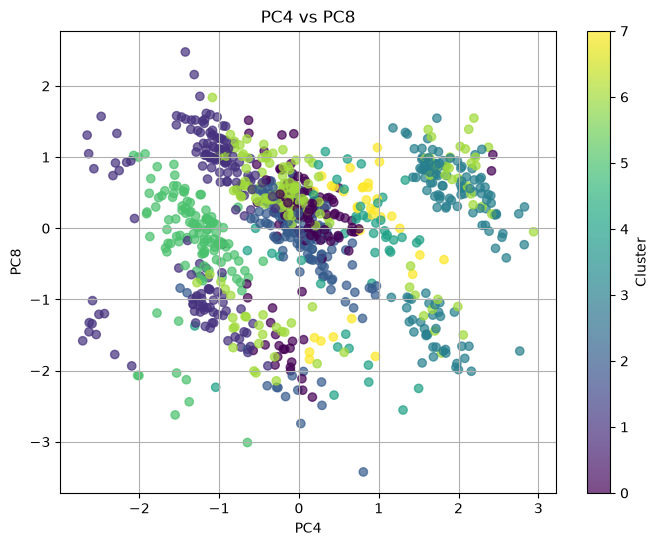

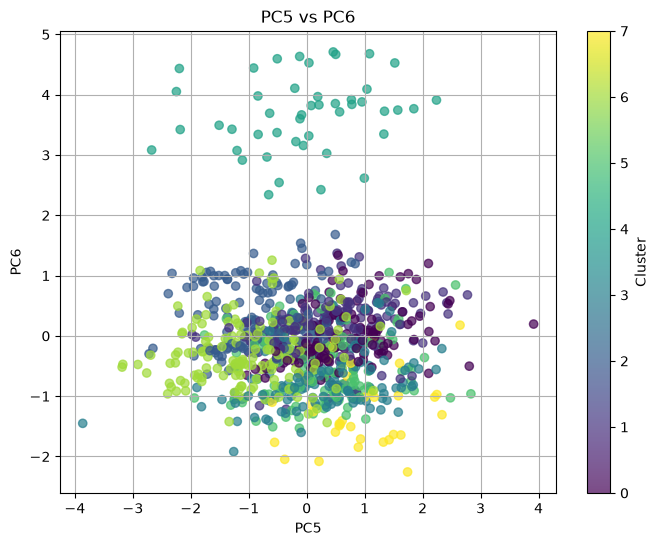

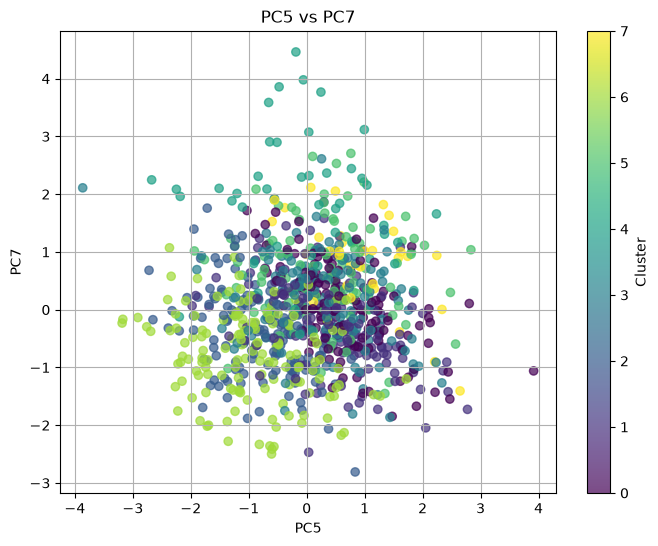

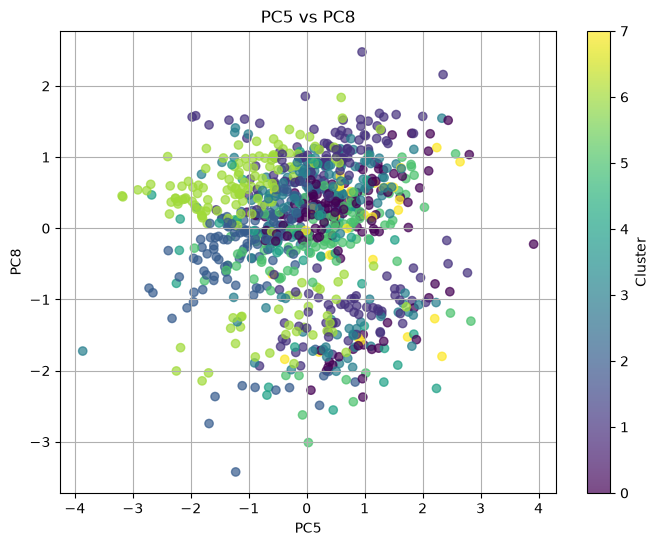

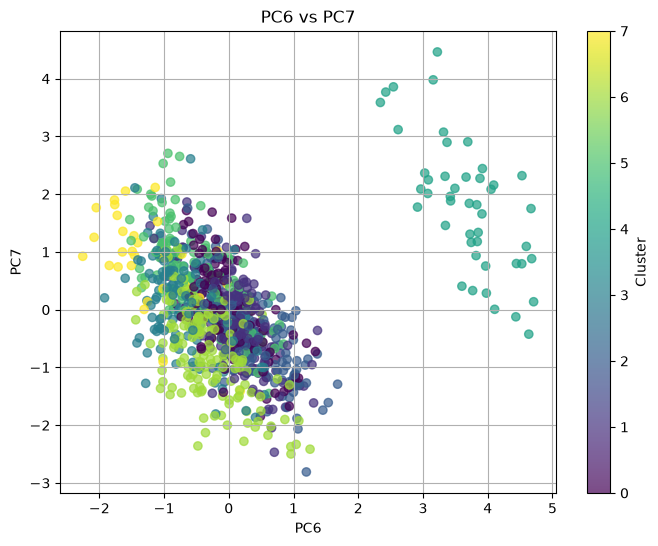

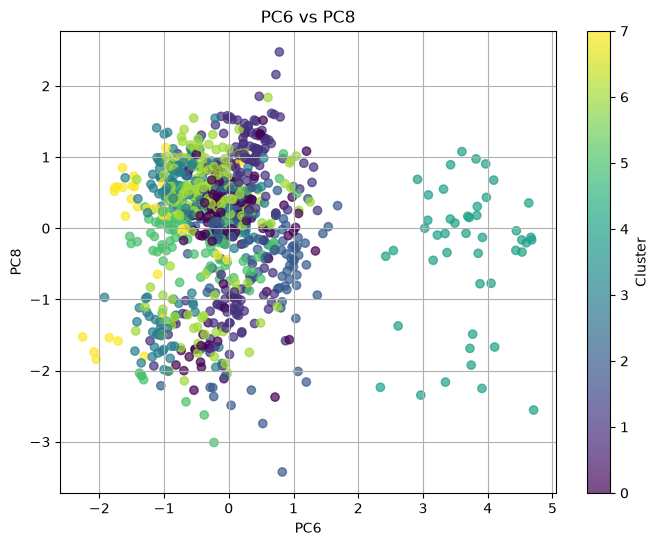

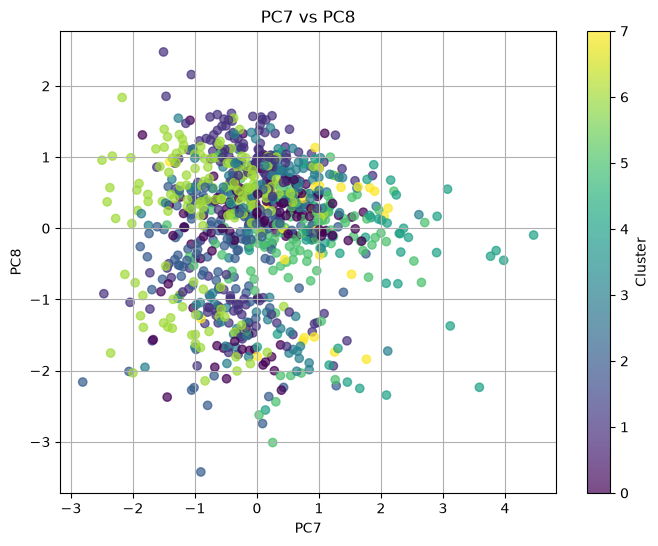

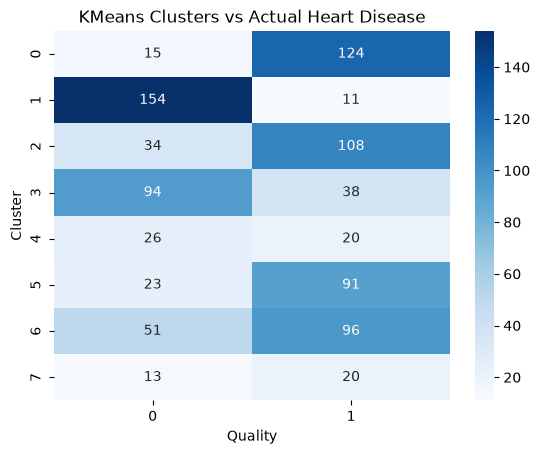

Silhouette: 0.2568564335839578
Davies-Bouldin: 1.2926811626131576
ARI: 0.10733376643309352
NMI: 0.14670334420710018


In [8]:
# helper functions to compare and visualize PC-variables

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)

def plot_pca_pairs(pca_result, components, target=None):
    num_c = pca_result.shape[1]

    # Get unique target classes
    if target is not None:
        classes = np.unique(target)
        colors = plt.cm.tab10(np.linspace(0, 1, len(classes)))

    # Process each pair of PC variables
    for i in range(num_c):
        for j in range(i + 1, num_c):
            plt.figure(figsize=(8, 6))

            if target is not None:
                for cls, color in zip(classes, colors):
                    mask = target == cls

                    plt.scatter(
                        pca_result[mask, i],
                        pca_result[mask, j],
                        color=color,
                        alpha=0.7,
                        label=str(cls)
                    )

                plt.legend(title="Target")

            else:
                plt.scatter(
                    pca_result[:, i],
                    pca_result[:, j],
                    alpha=0.7
                )

            plt.title(f"PC{i+1} vs PC{j+1}")
            plt.xlabel(f"PC{i+1}")
            plt.ylabel(f"PC{j+1}")
            plt.grid(True)
            plt.show()

def plot_pca_pairs_with_clustering(pca_result, components, n_clusters=3):
    num_c = pca_result.shape[1]
    
    # Apply KMeans clustering
    kmeans = KMeans(n_clusters=n_clusters, random_state=1874)
    cluster_labels = kmeans.fit_predict(pca_result)
    
    # Process each pair of PC-variables and plot clusters
    for i in range(num_c):
        for j in range(i + 1, num_c):
            plt.figure(figsize=(8, 6))
            scatter = plt.scatter(pca_result[:, i], pca_result[:, j], c=cluster_labels, cmap='viridis', alpha=0.7)
            plt.title(f"PC{i+1} vs PC{j+1}")
            plt.xlabel(f"PC{i+1}")
            plt.ylabel(f"PC{j+1}")
            plt.grid(True)
            plt.colorbar(scatter, label='Cluster')
            plt.show()

    comparison = pd.crosstab(
        pd.Series(cluster_labels, name="Cluster"),
        pd.Series(y, name="Quality")
    )

    sns.heatmap(comparison, annot=True, fmt="d", cmap="Blues")

    plt.title("KMeans Clusters vs Actual Heart Disease")
    plt.show()

    print("Silhouette:",
      silhouette_score(pca_result, cluster_labels))

    print("Davies-Bouldin:",
        davies_bouldin_score(pca_result, cluster_labels))

    print("ARI:",
        adjusted_rand_score(y, cluster_labels))

    print("NMI:",
        normalized_mutual_info_score(y, cluster_labels))

# plot_pca_pairs(X_pca, pca.components_, y)
# we can also use KMeans to visualize how well the data can be differentiated
# 3 is a good number to begin with for clusters, try also 6 (amount of options in the target)
plot_pca_pairs_with_clustering(X_pca, pca.components_, n_clusters=8)

The clusters capture some of the heart disease pattern, especially clusters 0 and 1, but they do not separate the target well on their own. They are more useful as support features for a model than as a classifier.